#Petite analyse d'un jeu de données avec Pandas et Matplotlib.

In [178]:
import datetime
import pandas as pd
import warnings
warnings.filterwarnings("ignore")

In [177]:
pd.options.display.float_format = "{:,.2f}".format #Me permet de mieux visualiser les nombres.
pd.set_option("display.max_columns", None) #Enlever les restrictions d'affichage sur les colonnes d'un dataset.
pd.set_option("display.max_rows", 20) #Limitation d'affichage sur le nombre de lignes d'un df.

In [87]:
train = pd.read_csv("/content/train.csv", low_memory=False, parse_dates=["Date"])

In [5]:
store = pd.read_csv("/content/store.csv")

In [179]:
train.head(5)

,Store,DayOfWeek,Date,Sales,Customers,Open,Promo,StateHoliday,SchoolHoliday
0,1,5,2015-07-31,5263,555,1,1,0,1
1,2,5,2015-07-31,6064,625,1,1,0,1
2,3,5,2015-07-31,8314,821,1,1,0,1
3,4,5,2015-07-31,13995,1498,1,1,0,1
4,5,5,2015-07-31,4822,559,1,1,0,1


In [180]:
train.shape

(1017209, 9)

In [181]:
store.head(5)

,Store,StoreType,Assortment,CompetitionDistance,CompetitionOpenSinceMonth,CompetitionOpenSinceYear,Promo2,Promo2SinceWeek,Promo2SinceYear,PromoInterval,CompetitionOpenSince,Promo2Since
0,1,c,a,"1,270.00",9,2008,0,0,0,0,2008-09-01 00:00:00,0
1,2,a,a,570.00,11,2007,1,13,2010,"Jan,Apr,Jul,Oct",2007-11-01 00:00:00,2010-03-29 00:00:00
2,3,a,a,"14,130.00",12,2006,1,14,2011,"Jan,Apr,Jul,Oct",2006-12-01 00:00:00,2011-04-04 00:00:00
3,4,c,c,620.00,9,2009,0,0,0,0,2009-09-01 00:00:00,0
4,5,a,a,"29,910.00",4,2015,0,0,0,0,2015-04-01 00:00:00,0


In [182]:
store.shape

(1115, 12)

In [183]:
magasin_train = train["Store"].unique()
debut = train["Date"].min()
fin = train["Date"].max()

In [184]:
print(f"Le fichier 'Train' contient des observations sur {len(magasin_train):,} magasins différents.")
print("L'historique va du {} au {}".format(debut.date(), fin.date()))

Le fichier 'Train' contient des observations sur 1,115 magasins différents.
L'historique va du 2013-01-01 au 2015-07-31


In [185]:
magasin_store = store["Store"].unique()

In [186]:
print(f"Le fichier 'Store' contient des observations sur {len(magasin_store):,} magasins différents")

Le fichier 'Store' contient des observations sur 1,115 magasins différents


In [187]:
taux_magasins_communs = len(set(magasin_train) & set(magasin_store)) / len(magasin_train)
print(f"{100* taux_magasins_communs}% des magasins du fichier 'Train' sont également dans le fichier 'Store.")

100.0% des magasins du fichier 'Train' sont également dans le fichier 'Store.


In [15]:
train.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1017209 entries, 0 to 1017208
Data columns (total 9 columns):
 #   Column         Non-Null Count    Dtype         
---  ------         --------------    -----         
 0   Store          1017209 non-null  int64         
 1   DayOfWeek      1017209 non-null  int64         
 2   Date           1017209 non-null  datetime64[ns]
 3   Sales          1017209 non-null  int64         
 4   Customers      1017209 non-null  int64         
 5   Open           1017209 non-null  int64         
 6   Promo          1017209 non-null  int64         
 7   StateHoliday   1017209 non-null  object        
 8   SchoolHoliday  1017209 non-null  int64         
dtypes: datetime64[ns](1), int64(7), object(1)
memory usage: 69.8+ MB


In [16]:
store.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1115 entries, 0 to 1114
Data columns (total 10 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   Store                      1115 non-null   int64  
 1   StoreType                  1115 non-null   object 
 2   Assortment                 1115 non-null   object 
 3   CompetitionDistance        1112 non-null   float64
 4   CompetitionOpenSinceMonth  761 non-null    float64
 5   CompetitionOpenSinceYear   761 non-null    float64
 6   Promo2                     1115 non-null   int64  
 7   Promo2SinceWeek            571 non-null    float64
 8   Promo2SinceYear            571 non-null    float64
 9   PromoInterval              571 non-null    object 
dtypes: float64(5), int64(2), object(3)
memory usage: 87.2+ KB


Pas très userfriendly, je vais plutôt créer une fonction réutilisable que je pourrai appliquer à n’importe quelle table.

In [188]:
def get_missing_values(df):
  number_missing = df.isna().sum()
  pct_missing = ((number_missing / len(df)) * 100).round(2)
  table = pd.DataFrame({
      'Nombre de valeurs manquantes': number_missing,
      'Pourcentage de valeurs manquantes': pct_missing
  }).sort_values(ascending=False, by=["Nombre de valeurs manquantes", "Pourcentage de valeurs manquantes"]).reset_index(names="Colonnes")
  return table

In [18]:
get_missing_values(train)

,Colonnes,Nombre de valeurs manquantes,Pourcentage de valeurs manquantes
0,Store,0,0.00
1,DayOfWeek,0,0.00
2,Date,0,0.00
3,Sales,0,0.00
4,Customers,0,0.00
5,Open,0,0.00
6,Promo,0,0.00
7,StateHoliday,0,0.00
8,SchoolHoliday,0,0.00


In [19]:
get_missing_values(store)

,Colonnes,Nombre de valeurs manquantes,Pourcentage de valeurs manquantes
0,Promo2SinceWeek,544,48.79
1,Promo2SinceYear,544,48.79
2,PromoInterval,544,48.79
3,CompetitionOpenSinceMonth,354,31.75
4,CompetitionOpenSinceYear,354,31.75
5,CompetitionDistance,3,0.27
6,Store,0,0.00
7,StoreType,0,0.00
8,Assortment,0,0.00
9,Promo2,0,0.00


On peut observer que 544 valeurs sont manquantes dans chacune des colonnes (Promo2SinceWeek, Promo2SinceYear et PromoInterval), soit près de la moitié des observations. On peut supposer que ces valeurs manquantes concernent uniquement les magasins qui ne participent pas au programme promotionnel Promo2.

In [20]:
all_promo_null = store[store[["Promo2SinceWeek", "Promo2SinceYear", "PromoInterval"]].isna().all(axis=1)]

Ici je vérifie si ce sont les mêmes magasins en question pour chaque ligne.

In [21]:
len(all_promo_null)

544

In [22]:
all_promo_null["Promo2"].value_counts()

,count
Promo2,
0,544


Nous avons donc bien confirmé notre hypothèse. On remplace les valeurs NULL par 0.

In [23]:
promo2colls = ["Promo2SinceWeek", "Promo2SinceYear", "PromoInterval"]
store[promo2colls] = store[promo2colls].fillna(0)

In [24]:
store

,Store,StoreType,Assortment,CompetitionDistance,CompetitionOpenSinceMonth,CompetitionOpenSinceYear,Promo2,Promo2SinceWeek,Promo2SinceYear,PromoInterval
0,1,c,a,"1,270.00",9.00,"2,008.00",0,0.00,0.00,0
1,2,a,a,570.00,11.00,"2,007.00",1,13.00,"2,010.00","Jan,Apr,Jul,Oct"
2,3,a,a,"14,130.00",12.00,"2,006.00",1,14.00,"2,011.00","Jan,Apr,Jul,Oct"
3,4,c,c,620.00,9.00,"2,009.00",0,0.00,0.00,0
4,5,a,a,"29,910.00",4.00,"2,015.00",0,0.00,0.00,0
...,...,...,...,...,...,...,...,...,...,...
1110,1111,a,a,"1,900.00",6.00,"2,014.00",1,31.00,"2,013.00","Jan,Apr,Jul,Oct"
1111,1112,c,c,"1,880.00",4.00,"2,006.00",0,0.00,0.00,0
1112,1113,a,c,"9,260.00",NaN,NaN,0,0.00,0.00,0
1113,1114,a,c,870.00,NaN,NaN,0,0.00,0.00,0


In [25]:
all_competition_null = store[store[["CompetitionOpenSinceMonth", "CompetitionOpenSinceYear"]].isna().all(axis=1)]
len(all_competition_null)

354

In [26]:
len(all_competition_null[all_competition_null["CompetitionDistance"]==0])

0

In [27]:
competition_cols = ["CompetitionOpenSinceMonth", "CompetitionOpenSinceYear"]
store[competition_cols] = store[competition_cols].fillna(0)

In [28]:
print("Valeur min de CompetitionDistance {} m".format(store["CompetitionDistance"].min()))
print("Valeur max de CompetitionDistance {} m".format(store["CompetitionDistance"].max()))
print("La moyenne de CompetitionDistance: {} m".format(store["CompetitionDistance"].mean().round(2)))
print("La médiane de CompetitionDistance: {} m".format(store["CompetitionDistance"].median()))

Valeur min de CompetitionDistance 20.0 m
Valeur max de CompetitionDistance 75860.0 m
La moyenne de CompetitionDistance: 5404.9 m
La médiane de CompetitionDistance: 2325.0 m


In [29]:
store["CompetitionDistance"] = store["CompetitionDistance"].fillna(store["CompetitionDistance"].median())

In [30]:
train

,Store,DayOfWeek,Date,Sales,Customers,Open,Promo,StateHoliday,SchoolHoliday
0,1,5,2015-07-31,5263,555,1,1,0,1
1,2,5,2015-07-31,6064,625,1,1,0,1
2,3,5,2015-07-31,8314,821,1,1,0,1
3,4,5,2015-07-31,13995,1498,1,1,0,1
4,5,5,2015-07-31,4822,559,1,1,0,1
...,...,...,...,...,...,...,...,...,...
1017204,1111,2,2013-01-01,0,0,0,0,a,1
1017205,1112,2,2013-01-01,0,0,0,0,a,1
1017206,1113,2,2013-01-01,0,0,0,0,a,1
1017207,1114,2,2013-01-01,0,0,0,0,a,1


In [31]:
store

,Store,StoreType,Assortment,CompetitionDistance,CompetitionOpenSinceMonth,CompetitionOpenSinceYear,Promo2,Promo2SinceWeek,Promo2SinceYear,PromoInterval
0,1,c,a,"1,270.00",9.00,"2,008.00",0,0.00,0.00,0
1,2,a,a,570.00,11.00,"2,007.00",1,13.00,"2,010.00","Jan,Apr,Jul,Oct"
2,3,a,a,"14,130.00",12.00,"2,006.00",1,14.00,"2,011.00","Jan,Apr,Jul,Oct"
3,4,c,c,620.00,9.00,"2,009.00",0,0.00,0.00,0
4,5,a,a,"29,910.00",4.00,"2,015.00",0,0.00,0.00,0
...,...,...,...,...,...,...,...,...,...,...
1110,1111,a,a,"1,900.00",6.00,"2,014.00",1,31.00,"2,013.00","Jan,Apr,Jul,Oct"
1111,1112,c,c,"1,880.00",4.00,"2,006.00",0,0.00,0.00,0
1112,1113,a,c,"9,260.00",0.00,0.00,0,0.00,0.00,0
1113,1114,a,c,870.00,0.00,0.00,0,0.00,0.00,0


In [32]:
print("La shape du fichier 'Train' est de {}.".format(train.shape))
print("La shape du fichier 'Store' et de {}.".format(store.shape))

La shape du fichier 'Train' est de (1017209, 9).
La shape du fichier 'Store' et de (1115, 10).


In [33]:
df = train.merge(store, on="Store", how="left")

In [34]:
print("La shape après la jointure des deux fichiers est: {}.".format(df.shape))

La shape après la jointure des deux fichiers est: (1017209, 18).


In [35]:
cols_order = ["Store",
    "StoreType",
    "Assortment",
    "CompetitionDistance",
    "CompetitionOpenSinceMonth",
    "CompetitionOpenSinceYear",
    "Promo2",
    "Promo2SinceWeek",
    "Promo2SinceYear",
    "PromoInterval",
    "Date",
    "DayOfWeek",
    "Open",
    "Promo",
    "StateHoliday",
    "SchoolHoliday",
    "Customers",
    "Sales"]

In [36]:
df = df[cols_order]

In [37]:
df.sort_values(by=["Store", "Date"])

,Store,StoreType,Assortment,CompetitionDistance,CompetitionOpenSinceMonth,CompetitionOpenSinceYear,Promo2,Promo2SinceWeek,Promo2SinceYear,PromoInterval,Date,DayOfWeek,Open,Promo,StateHoliday,SchoolHoliday,Customers,Sales
1016095,1,c,a,"1,270.00",9.00,"2,008.00",0,0.00,0.00,0,2013-01-01,2,0,0,a,1,0,0
1014980,1,c,a,"1,270.00",9.00,"2,008.00",0,0.00,0.00,0,2013-01-02,3,1,0,0,1,668,5530
1013865,1,c,a,"1,270.00",9.00,"2,008.00",0,0.00,0.00,0,2013-01-03,4,1,0,0,1,578,4327
1012750,1,c,a,"1,270.00",9.00,"2,008.00",0,0.00,0.00,0,2013-01-04,5,1,0,0,1,619,4486
1011635,1,c,a,"1,270.00",9.00,"2,008.00",0,0.00,0.00,0,2013-01-05,6,1,0,0,1,635,4997
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
5574,1115,d,c,"5,350.00",0.00,0.00,1,22.00,"2,012.00","Mar,Jun,Sept,Dec",2015-07-27,1,1,1,0,1,608,10712
4459,1115,d,c,"5,350.00",0.00,0.00,1,22.00,"2,012.00","Mar,Jun,Sept,Dec",2015-07-28,2,1,1,0,1,500,8093
3344,1115,d,c,"5,350.00",0.00,0.00,1,22.00,"2,012.00","Mar,Jun,Sept,Dec",2015-07-29,3,1,1,0,1,473,7661
2229,1115,d,c,"5,350.00",0.00,0.00,1,22.00,"2,012.00","Mar,Jun,Sept,Dec",2015-07-30,4,1,1,0,1,502,8405


In [38]:
get_missing_values(df)

,Colonnes,Nombre de valeurs manquantes,Pourcentage de valeurs manquantes
0,Store,0,0.00
1,StoreType,0,0.00
2,Assortment,0,0.00
3,CompetitionDistance,0,0.00
4,CompetitionOpenSinceMonth,0,0.00
5,CompetitionOpenSinceYear,0,0.00
6,Promo2,0,0.00
7,Promo2SinceWeek,0,0.00
8,Promo2SinceYear,0,0.00
9,PromoInterval,0,0.00


**Place à l'étude statistique**

In [39]:
df["Sales"].describe()

,Sales
count,"1,017,209.00"
mean,"5,773.82"
std,"3,849.93"
min,0.00
25%,"3,727.00"
50%,"5,744.00"
75%,"7,856.00"
max,"41,551.00"


In [40]:
import matplotlib
import matplotlib.pyplot as plt
%matplotlib inline
from matplotlib.dates import DateFormatter
import seaborn as sns
sns.set(color_codes = True)
sns.set_style("whitegrid")

In [41]:
def show_distribution(df, var):
  #stats
  print("Moyenne: {}".format(round(df[var].mean(), 2)))
  print("Mediane: {}".format(round(df[var].median(), 2)))
  print("Valeur la plus fréquente: {}".format(df[var].mode()[0]))
  print("Valeur Max: {}".format(round(df[var].max(), 2)))
  print("Valeur Min: {}".format(round(df[var].min(), 2)))

  #créer les graphs
  plt.figure(figsize=(15,5))

  #hist
  plt.subplot(1, 2, 1)
  sns.histplot(df[var], bins= 30)
  plt.title(f"Histogramme de {var}.")

  #boxplot
  plt.subplot(1, 2, 2)
  sns.boxplot(x=df[var])
  plt.title(f"Box de {var}.")

  plt.show()



Moyenne: 5773.82
Mediane: 5744.0
Valeur la plus fréquente: 0
Valeur Max: 41551
Valeur Min: 0


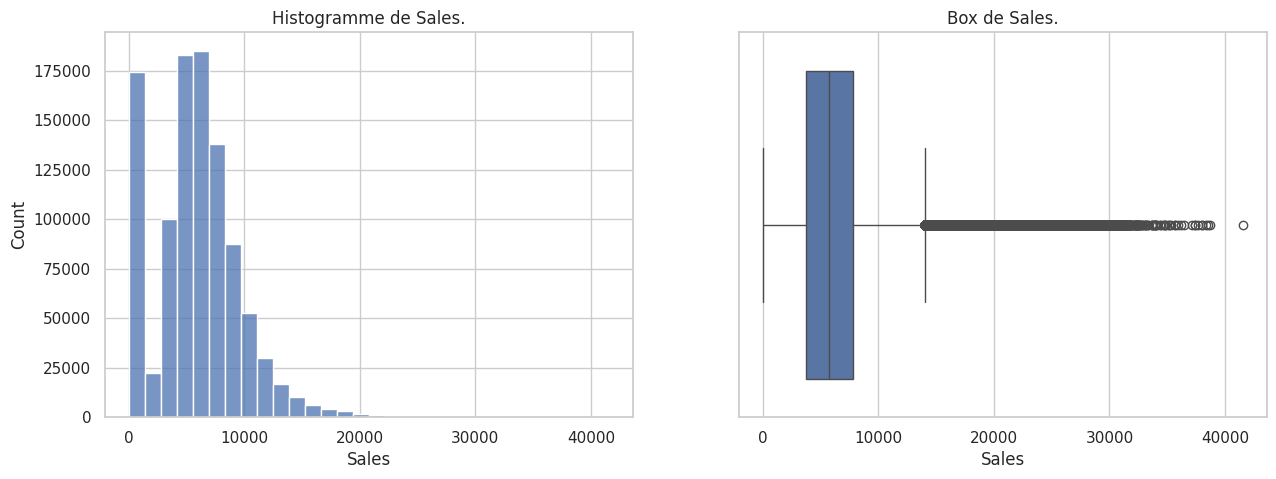

In [42]:
show_distribution(df, "Sales")

La valeur 0 est la plus fréquente. Celle-ci correspondrait aux jours où le magasin est fermé. Si cette hypothèse est valide, ces observations pourraient être supprimées du jeu de données lors des phases de modélisation.

Pour les ventes non nulles, la distribution présente une légère asymétrie positive (positive skeweness, i.e. la distribution est légérement décalée à gauche de la médiane, avec une queue de distribution étalée vers la droite). Une log-normalization pourrait être intéressante à investiguer pour normaliser la distribution.

La majorité des valeurs se situent entre 0 et 15k. La valeur maximale est de 41.5k. Les valeurs de ventes supérieures au seuil de 15k pourrait être des valeurs aberrantes ou alors des bons jours de ventes. On a pas assez d'infos pour l'instant.

In [43]:
df[df["Sales"] == 0]["Open"].value_counts()

,count
Open,
0,172817
1,54


In [44]:
df[(df["Sales"] == 0) & (df["Open"] == 1)]["Store"].nunique()

41

On va analyser les ventes sans compter les jours où les magasins étaient fermés.

In [145]:
sales_filtered = df[(df["Sales"] > 0) & (df["Sales"] < 15000)]

Moyenne: 6687.54
Mediane: 6295.0
Valeur la plus fréquente: 5674
Valeur Max: 14999
Valeur Min: 46


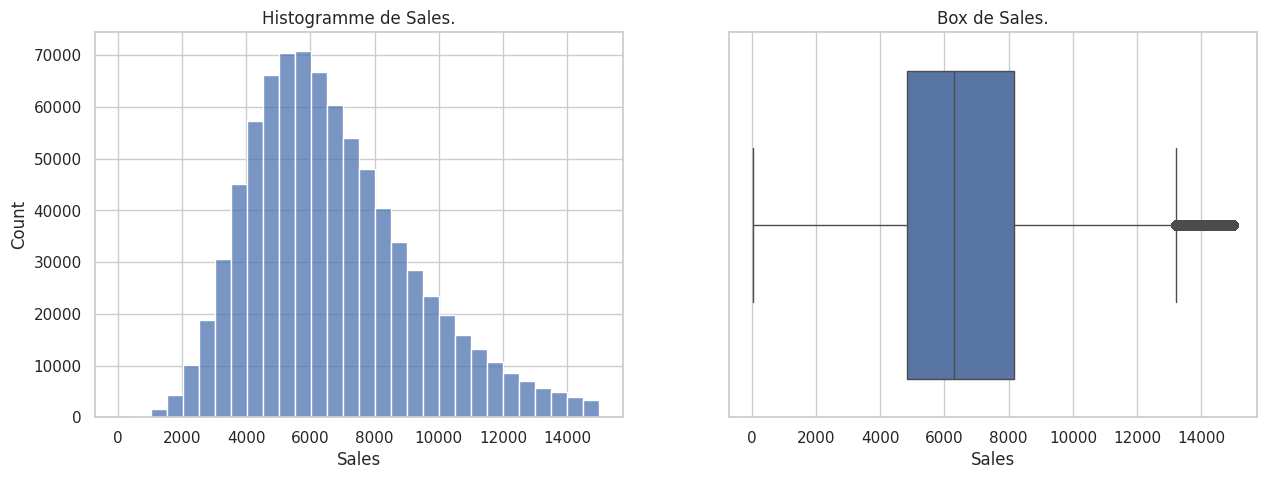

In [146]:
show_distribution(sales_filtered, "Sales")

Moyenne: 633.15
Mediane: 609.0
Valeur la plus fréquente: 0
Valeur Max: 7388
Valeur Min: 0


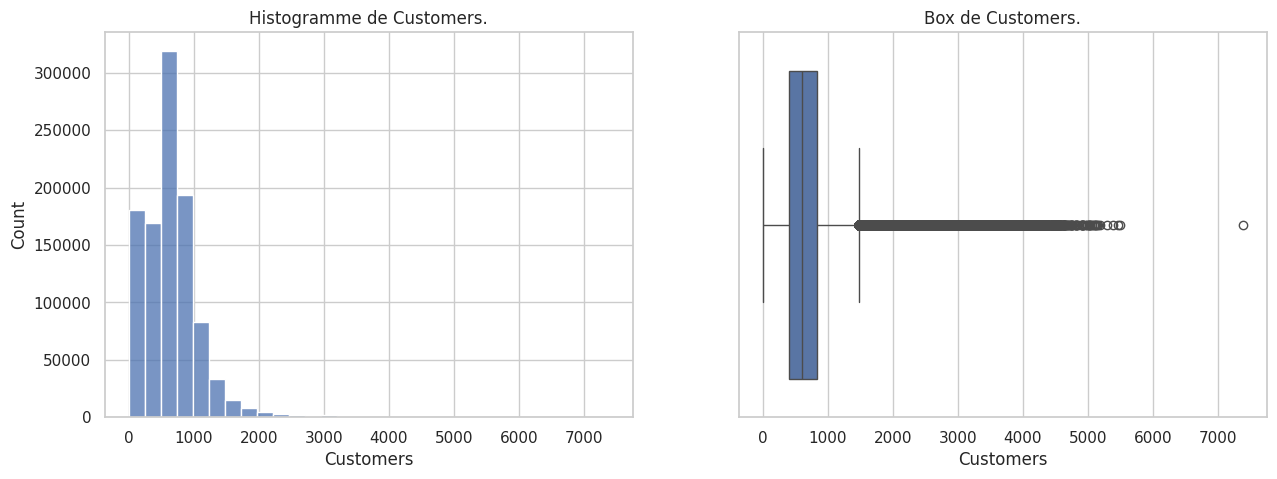

In [147]:
show_distribution(df, "Customers")

On va s'interesser aux colonnes Sales et Customers afin de découvrir le panier moyen des magasins, ainsi que d'autres stats.

In [148]:
df["Panier Moyen"] = df["Sales"] / df["Customers"]

In [149]:
df

,Store,StoreType,Assortment,CompetitionDistance,CompetitionOpenSinceMonth,CompetitionOpenSinceYear,Promo2,Promo2SinceWeek,Promo2SinceYear,PromoInterval,Date,DayOfWeek,Open,Promo,StateHoliday,SchoolHoliday,Customers,Sales,Panier Moyen
0,1,c,a,"1,270.00",9.00,"2,008.00",0,0.00,0.00,0,2015-07-31,5,1,1,0,1,555,5263,9.48
1,2,a,a,570.00,11.00,"2,007.00",1,13.00,"2,010.00","Jan,Apr,Jul,Oct",2015-07-31,5,1,1,0,1,625,6064,9.70
2,3,a,a,"14,130.00",12.00,"2,006.00",1,14.00,"2,011.00","Jan,Apr,Jul,Oct",2015-07-31,5,1,1,0,1,821,8314,10.13
3,4,c,c,620.00,9.00,"2,009.00",0,0.00,0.00,0,2015-07-31,5,1,1,0,1,1498,13995,9.34
4,5,a,a,"29,910.00",4.00,"2,015.00",0,0.00,0.00,0,2015-07-31,5,1,1,0,1,559,4822,8.63
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1017204,1111,a,a,"1,900.00",6.00,"2,014.00",1,31.00,"2,013.00","Jan,Apr,Jul,Oct",2013-01-01,2,0,0,a,1,0,0,NaN
1017205,1112,c,c,"1,880.00",4.00,"2,006.00",0,0.00,0.00,0,2013-01-01,2,0,0,a,1,0,0,NaN
1017206,1113,a,c,"9,260.00",0.00,0.00,0,0.00,0.00,0,2013-01-01,2,0,0,a,1,0,0,NaN
1017207,1114,a,c,870.00,0.00,0.00,0,0.00,0.00,0,2013-01-01,2,0,0,a,1,0,0,NaN


Moyenne: 9.49
Mediane: 9.25
Valeur la plus fréquente: 9.0
Valeur Max: 64.96
Valeur Min: 0.0


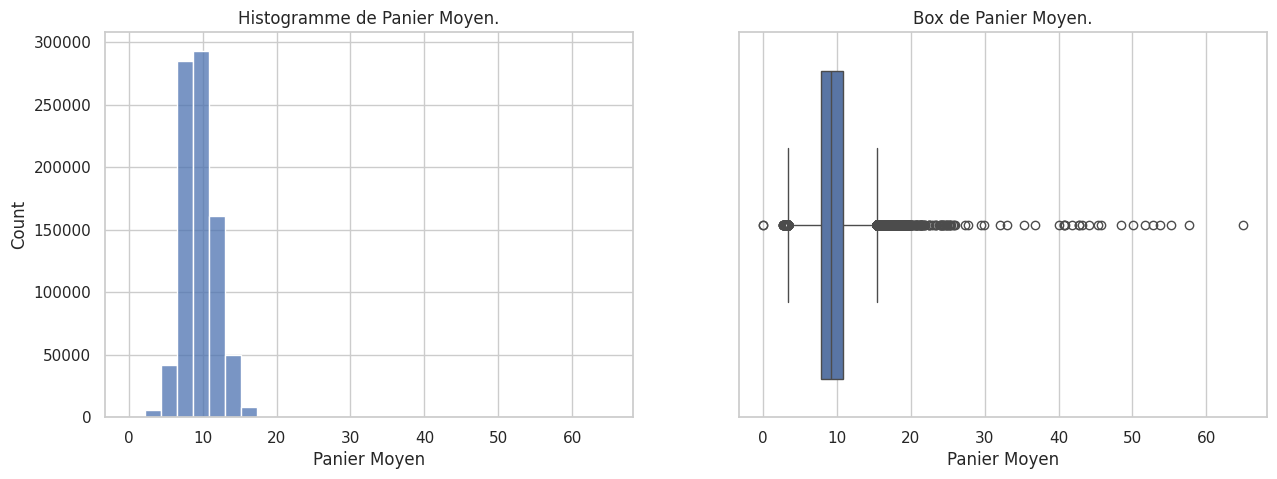

In [150]:
show_distribution(df, "Panier Moyen")

Moyenne: 5422.02
Mediane: 2325.0
Valeur la plus fréquente: 250.0
Valeur Max: 75860.0
Valeur Min: 20.0


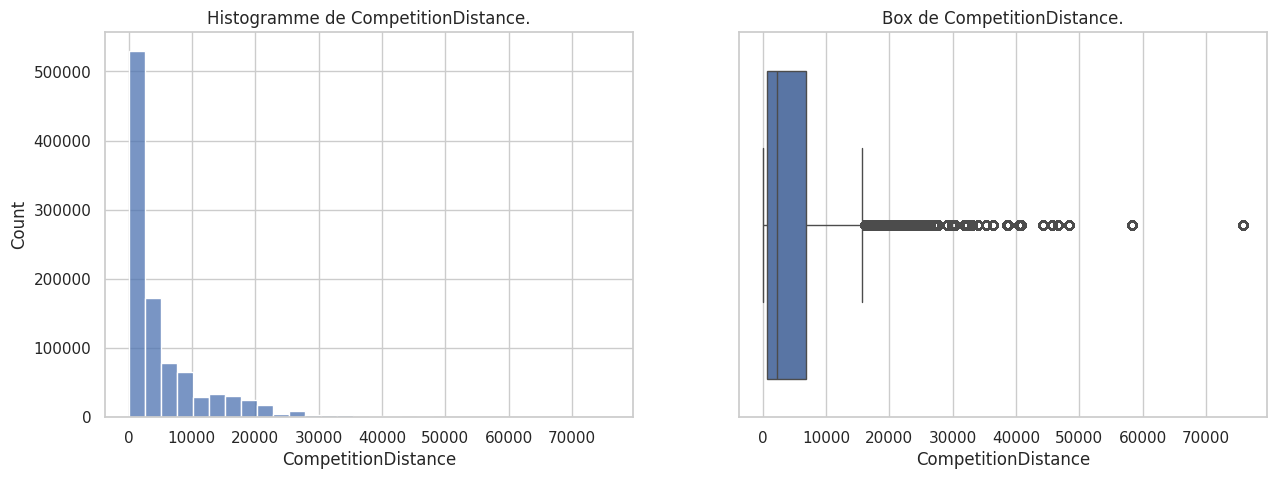

In [151]:
show_distribution(df, "CompetitionDistance")

In [152]:
df["StoreType"].value_counts()["a"]

np.int64(551627)

In [153]:
df.groupby("StoreType").agg({"Store":"count"})

,Store
StoreType,
a,551627
b,15830
c,136840
d,312912


In [81]:
def show_counts(df, var, order=True, group=None, palette="Blues", figsize=(15, 5)):
  plt.figure(figsize=figsize)
  if order:
    categories = df[var].value_counts().index
  else:
    categories = sorted(df[var].dropna().unique())

  ax = sns.countplot(data= df, x=var, order=categories, hue=group, palette=palette)

  for i in ax.patches:
    hauteur = i.get_height()

    if hauteur > 0:
      pourcentage = round(hauteur / len(df) * 100, 2)

      ax.text(
          i.get_x() + i.get_width() / 2,
          hauteur + 3,
          f"{pourcentage}%",
          ha="center"
      )
  plt.title("Répartition de " + var)
  plt.tight_layout()
  plt.show()

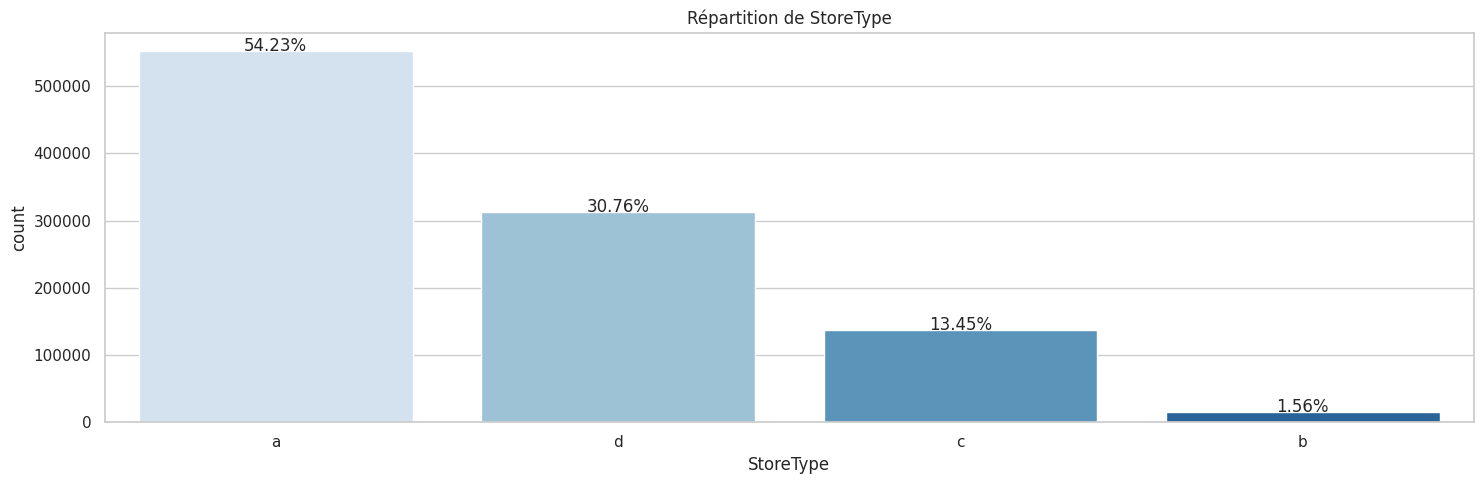

In [154]:
show_counts(df, "StoreType")

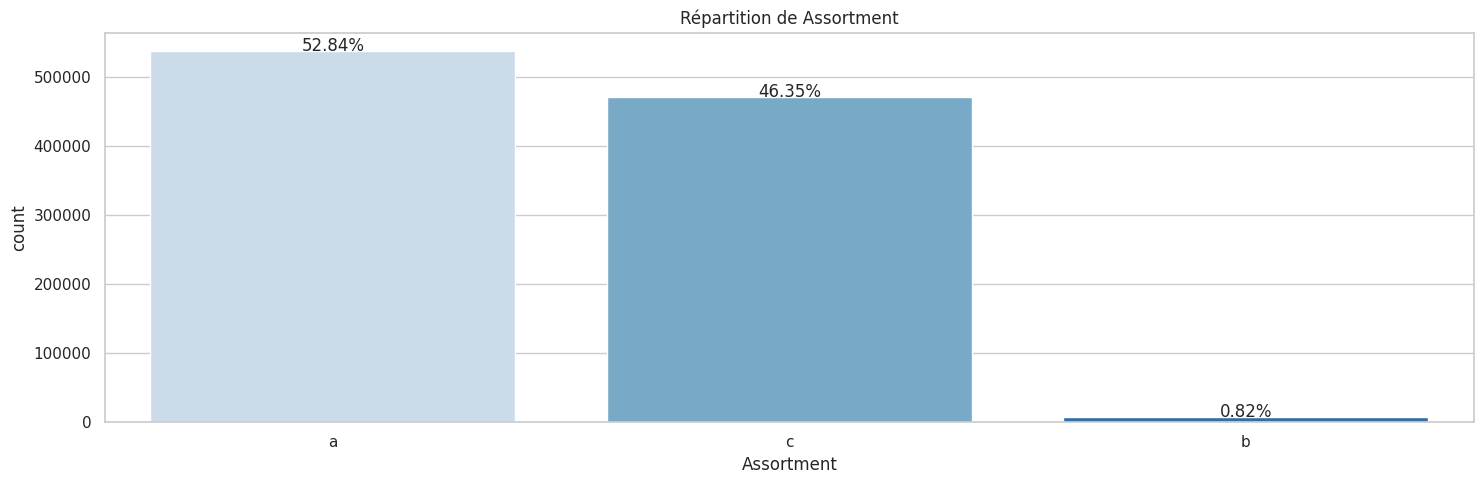

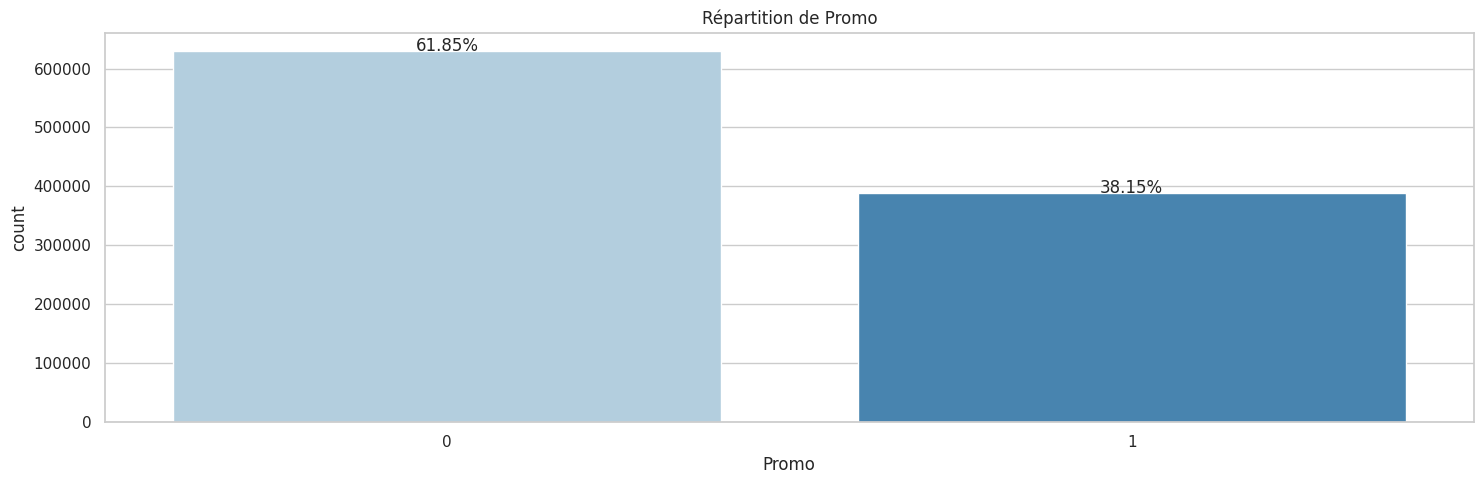

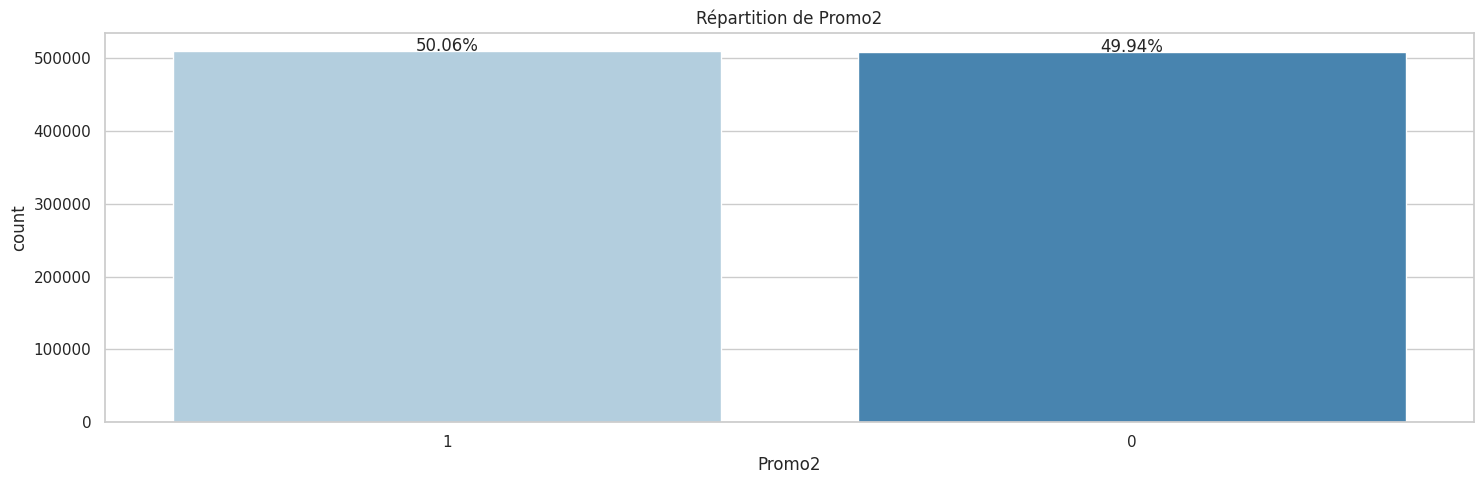

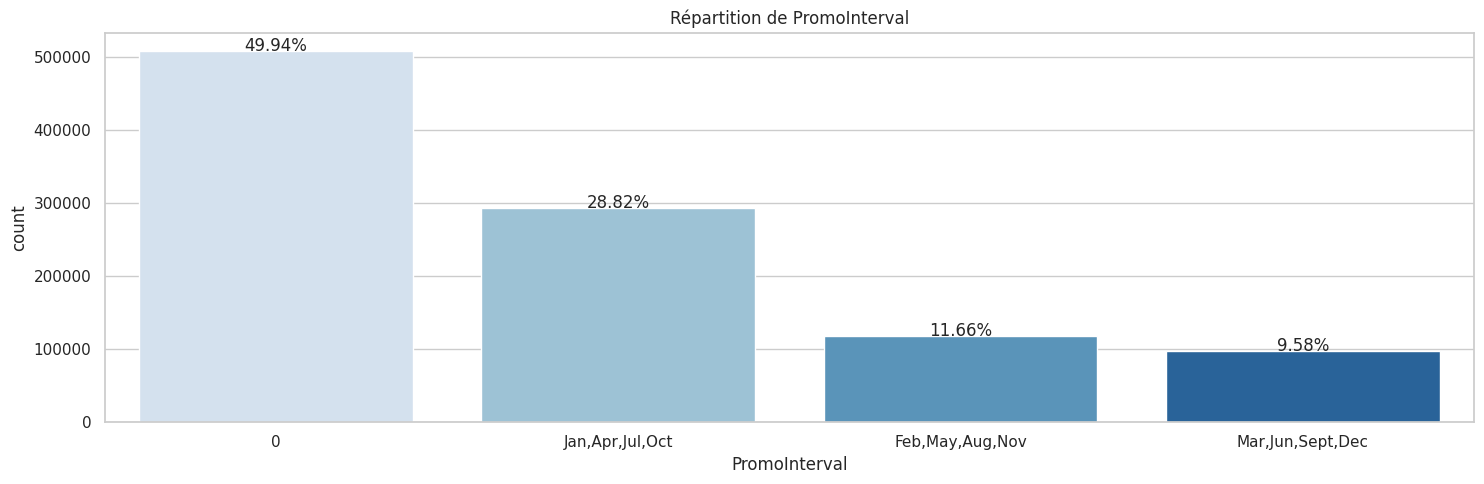

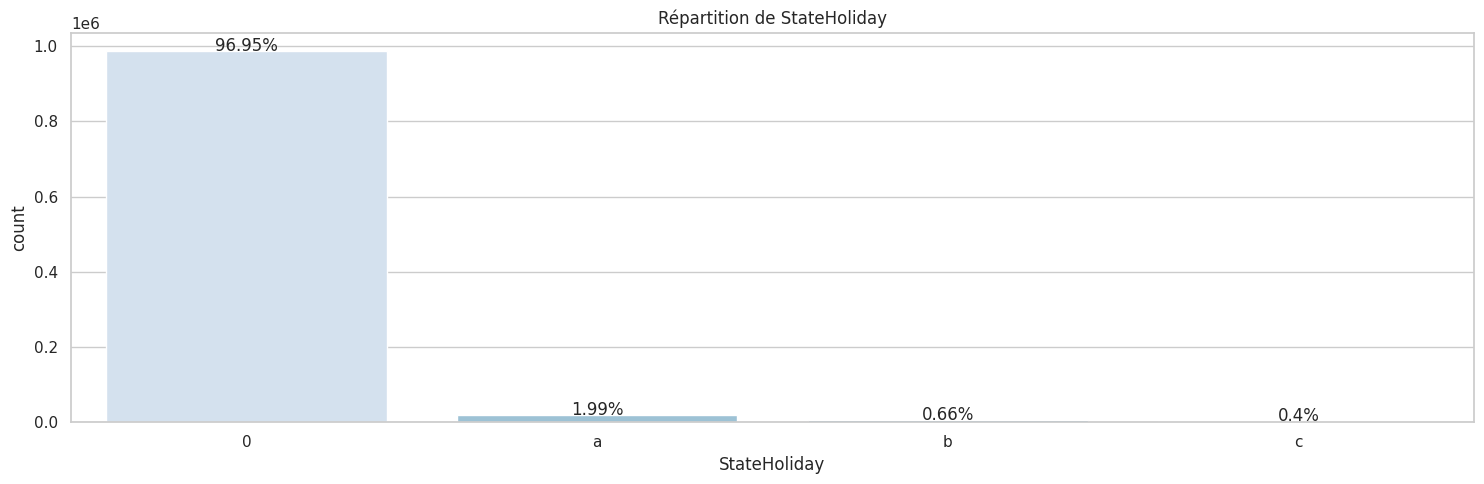

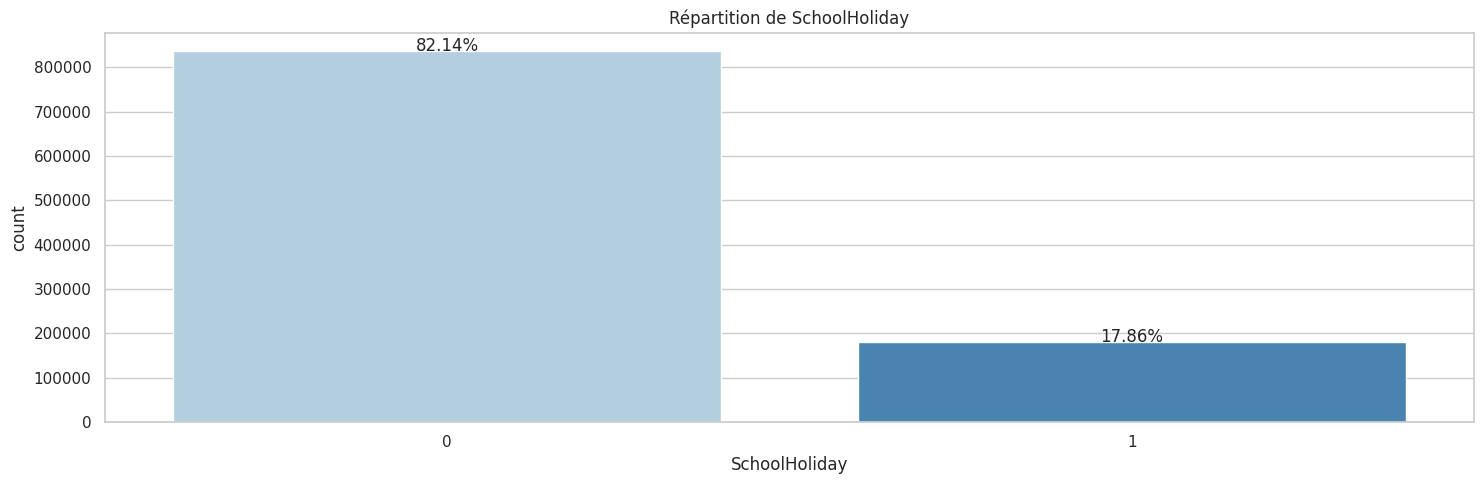

In [155]:
for col in ["Assortment", "Promo", "Promo2", "PromoInterval", "StateHoliday", "SchoolHoliday"]:
  show_counts(df, col)

On continue avec une analyse temporelle.

Je vais commencer par extraire les jours, les mois et les années.

In [156]:
df["Day"] = df["Date"].dt.day
df["Month"] = df["Date"].dt.month
df["Year"] = df["Date"].dt.year

In [157]:
df

,Store,StoreType,Assortment,CompetitionDistance,CompetitionOpenSinceMonth,CompetitionOpenSinceYear,Promo2,Promo2SinceWeek,Promo2SinceYear,PromoInterval,Date,DayOfWeek,Open,Promo,StateHoliday,SchoolHoliday,Customers,Sales,Panier Moyen,Day,Month,Year
0,1,c,a,"1,270.00",9.00,"2,008.00",0,0.00,0.00,0,2015-07-31,5,1,1,0,1,555,5263,9.48,31,7,2015
1,2,a,a,570.00,11.00,"2,007.00",1,13.00,"2,010.00","Jan,Apr,Jul,Oct",2015-07-31,5,1,1,0,1,625,6064,9.70,31,7,2015
2,3,a,a,"14,130.00",12.00,"2,006.00",1,14.00,"2,011.00","Jan,Apr,Jul,Oct",2015-07-31,5,1,1,0,1,821,8314,10.13,31,7,2015
3,4,c,c,620.00,9.00,"2,009.00",0,0.00,0.00,0,2015-07-31,5,1,1,0,1,1498,13995,9.34,31,7,2015
4,5,a,a,"29,910.00",4.00,"2,015.00",0,0.00,0.00,0,2015-07-31,5,1,1,0,1,559,4822,8.63,31,7,2015
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1017204,1111,a,a,"1,900.00",6.00,"2,014.00",1,31.00,"2,013.00","Jan,Apr,Jul,Oct",2013-01-01,2,0,0,a,1,0,0,NaN,1,1,2013
1017205,1112,c,c,"1,880.00",4.00,"2,006.00",0,0.00,0.00,0,2013-01-01,2,0,0,a,1,0,0,NaN,1,1,2013
1017206,1113,a,c,"9,260.00",0.00,0.00,0,0.00,0.00,0,2013-01-01,2,0,0,a,1,0,0,NaN,1,1,2013
1017207,1114,a,c,870.00,0.00,0.00,0,0.00,0.00,0,2013-01-01,2,0,0,a,1,0,0,NaN,1,1,2013


In [57]:
store["CompetitionOpenSinceYear"] = store["CompetitionOpenSinceYear"].astype(int)
store["CompetitionOpenSinceMonth"] = store["CompetitionOpenSinceMonth"].astype(int)

In [58]:
store

,Store,StoreType,Assortment,CompetitionDistance,CompetitionOpenSinceMonth,CompetitionOpenSinceYear,Promo2,Promo2SinceWeek,Promo2SinceYear,PromoInterval
0,1,c,a,"1,270.00",9,2008,0,0.00,0.00,0
1,2,a,a,570.00,11,2007,1,13.00,"2,010.00","Jan,Apr,Jul,Oct"
2,3,a,a,"14,130.00",12,2006,1,14.00,"2,011.00","Jan,Apr,Jul,Oct"
3,4,c,c,620.00,9,2009,0,0.00,0.00,0
4,5,a,a,"29,910.00",4,2015,0,0.00,0.00,0
...,...,...,...,...,...,...,...,...,...,...
1110,1111,a,a,"1,900.00",6,2014,1,31.00,"2,013.00","Jan,Apr,Jul,Oct"
1111,1112,c,c,"1,880.00",4,2006,0,0.00,0.00,0
1112,1113,a,c,"9,260.00",0,0,0,0.00,0.00,0
1113,1114,a,c,870.00,0,0,0,0.00,0.00,0


In [189]:
def premiere_date_concu(row):
  try:
    month = int(row["CompetitionOpenSinceMonth"])
    year = int(row["CompetitionOpenSinceYear"])
    date = pd.to_datetime(datetime.date(year, month, 1))
    return date
  except:
    return 0

In [190]:
store["CompetitionOpenSince"] = store.apply(premiere_date_concu, axis=1)

In [91]:
df = pd.merge(df, store[["Store", "CompetitionOpenSince"]], on= "Store", how="left")

In [94]:
store.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1115 entries, 0 to 1114
Data columns (total 11 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   Store                      1115 non-null   int64  
 1   StoreType                  1115 non-null   object 
 2   Assortment                 1115 non-null   object 
 3   CompetitionDistance        1115 non-null   float64
 4   CompetitionOpenSinceMonth  1115 non-null   int64  
 5   CompetitionOpenSinceYear   1115 non-null   int64  
 6   Promo2                     1115 non-null   int64  
 7   Promo2SinceWeek            1115 non-null   float64
 8   Promo2SinceYear            1115 non-null   float64
 9   PromoInterval              1115 non-null   object 
 10  CompetitionOpenSince       1115 non-null   object 
dtypes: float64(3), int64(4), object(4)
memory usage: 95.9+ KB


In [98]:
store["Promo2SinceWeek"] = store["Promo2SinceWeek"].astype(int)
store["Promo2SinceYear"] = store["Promo2SinceYear"].astype(int)

In [193]:
def premiere_promo(row):
  if row["Promo2SinceYear"] != 0:
    year = str(int(row["Promo2SinceYear"]))
    week = str(int(row["Promo2SinceWeek"]))
    d = year + "-W" + week
    return datetime.datetime.strptime(d + "-1", "%Y-W%W-%w")
  else:
    return 0

In [194]:
store["Promo2Since"] = store.apply(lambda row: premiere_promo(row), axis=1)

In [109]:
df = pd.merge(df, store[["Store", "Promo2Since"]], on= "Store", how="left")

In [112]:
sales_by_date = df.groupby("Date").agg({"Sales":["mean", "std"]})

In [115]:
sales_by_date.loc["2014"].head()

Sales         
               mean      std
Date                        
2014-01-01 5,792.41 2,947.61
2014-01-02 6,132.97 2,070.54
2014-01-03 6,197.32 2,019.78
2014-01-04 5,587.56 2,366.12
2014-01-05 7,117.50 3,537.05

In [116]:
sales_by_date.loc["2014-05"].head()

Sales         
               mean      std
Date                        
2014-05-01 8,726.27 3,871.35
2014-05-02 9,442.38 2,492.99
2014-05-03 5,997.43 2,454.15
2014-05-04 5,061.83 3,305.86
2014-05-05 9,144.07 2,420.55

In [196]:
def evolution_temp(df,
                       date_col = "Date",
                       target_col = "Sales",
                       agg=["mean", "std"],
                       filter_date1 = None,
                       filter_date2 = None,
                       figsize=(15,5)):

    var_by_date = df.groupby(date_col).agg({target_col:agg})

    if filter_date1 is not None and filter_date2 is None:
        var_by_date = var_by_date.loc[filter_date1]
    elif all(date is not None for date in [filter_date1, filter_date2]):
        var_by_date = var_by_date.loc[filter_date1:filter_date2]

    var_by_date.plot(figsize=figsize)
    plt.title('Evolution temporelle - ' + target_col + ' - ' + str(agg))
    plt.ylabel(target_col + ' - ' + str(agg))
    plt.show()



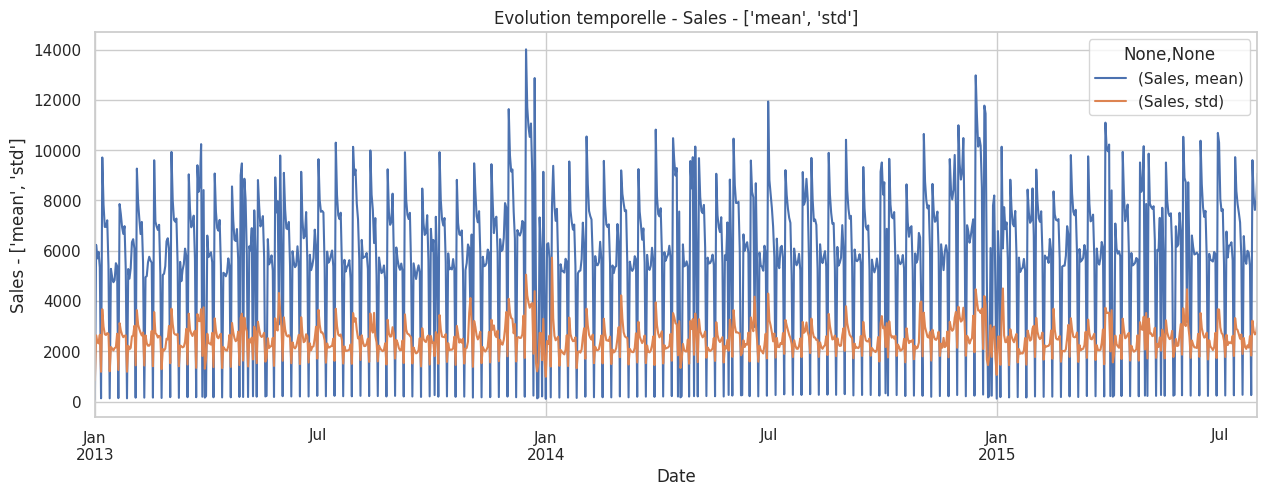

In [197]:
evolution_temp(df, date_col = "Date", target_col="Sales",agg=["mean", "std"])

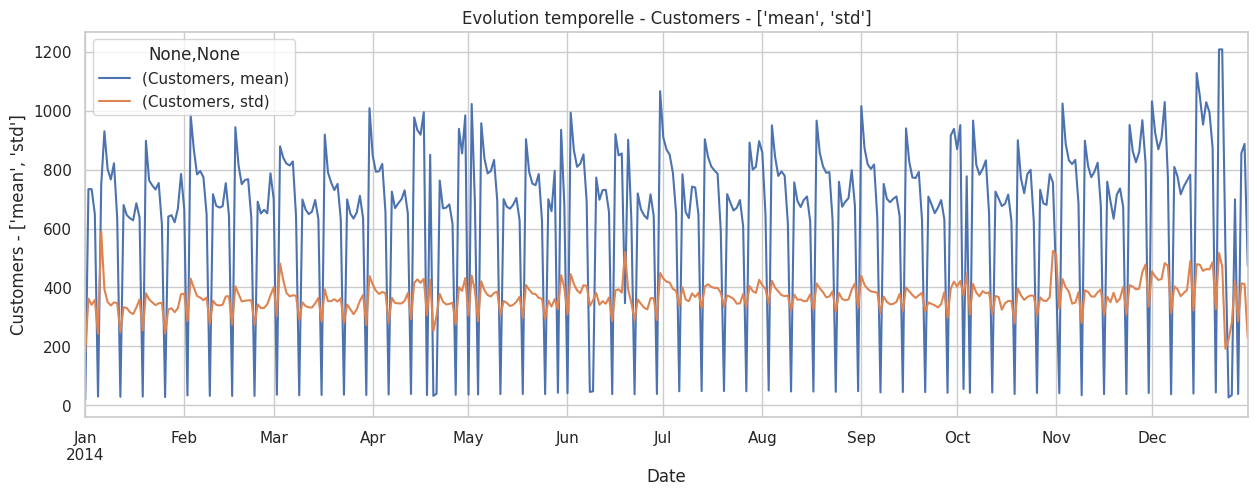

In [198]:
evolution_temp(df, date_col = "Date", target_col="Customers",agg=["mean", "std"], filter_date1="2014")

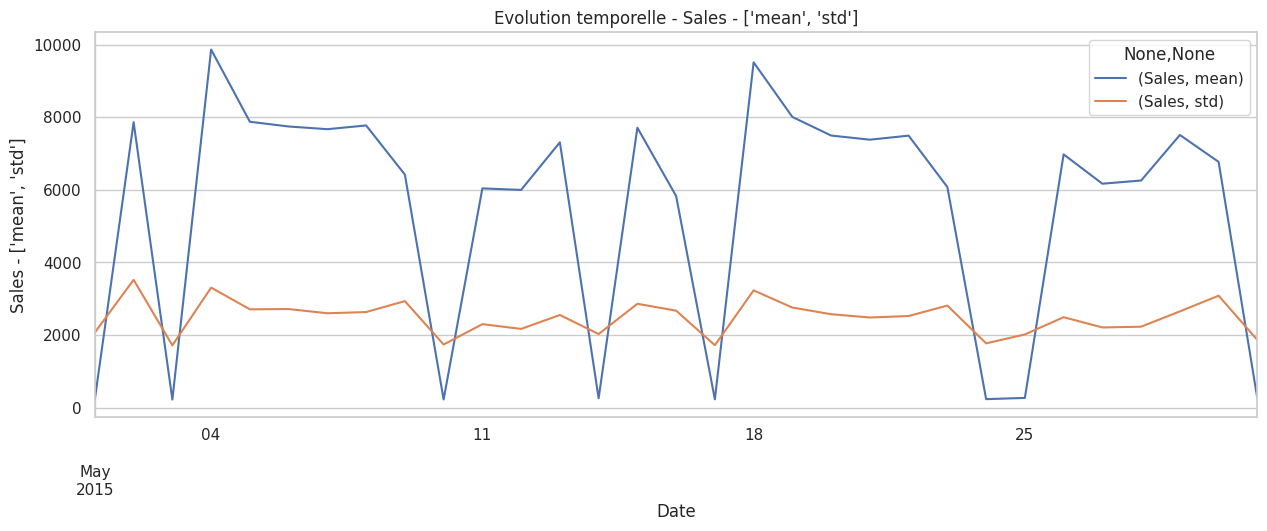

In [199]:
evolution_temp(df, date_col="Date", target_col="Sales", agg=["mean","std"], filter_date1="2015/05")

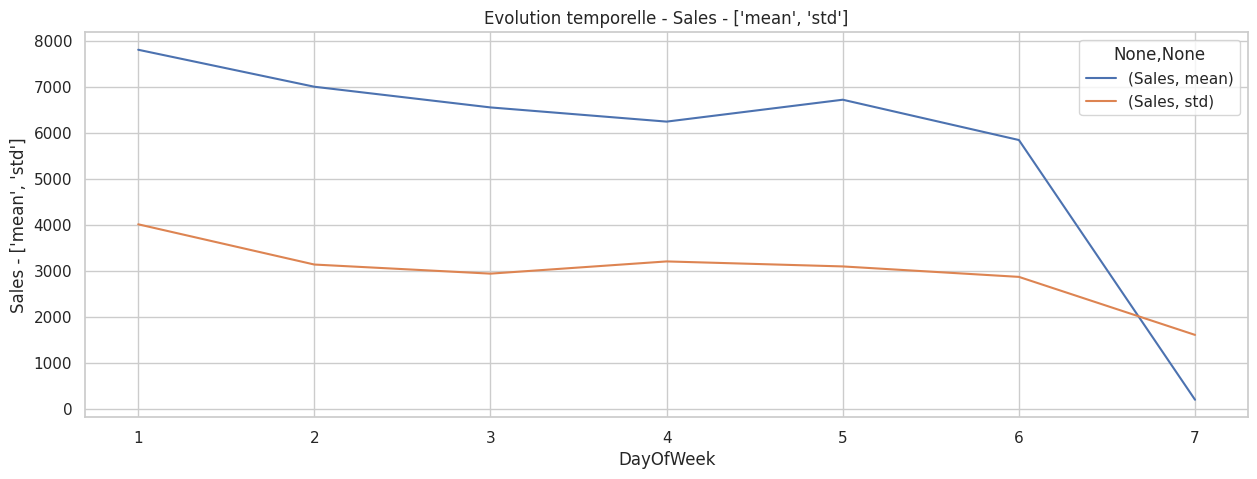

In [200]:
evolution_temp(df, date_col="DayOfWeek", target_col="Sales", agg=["mean","std"], filter_date1=None)

In [162]:
sales_by_week = df.groupby("DayOfWeek")["Sales"].mean().reset_index()

In [163]:
sales_by_week

,DayOfWeek,Sales
0,1,"7,809.04"
1,2,"7,005.24"
2,3,"6,555.88"
3,4,"6,247.58"
4,5,"6,723.27"
5,6,"5,847.56"
6,7,204.18


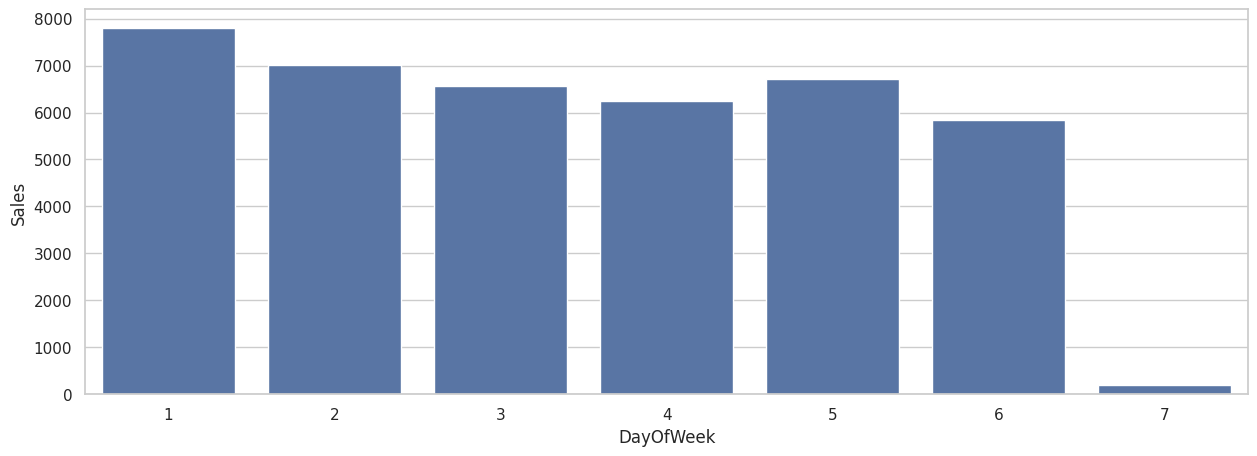

In [164]:
fig, ax = plt.subplots(1, figsize=(15, 5))
sns.barplot(data = sales_by_week, x="DayOfWeek", y="Sales", ax=ax)
plt.show()

On peut observer une baisse drastique des ventes le dimanche, qui s’explique par la fermeture de la majorité des magasins ce jour-là.

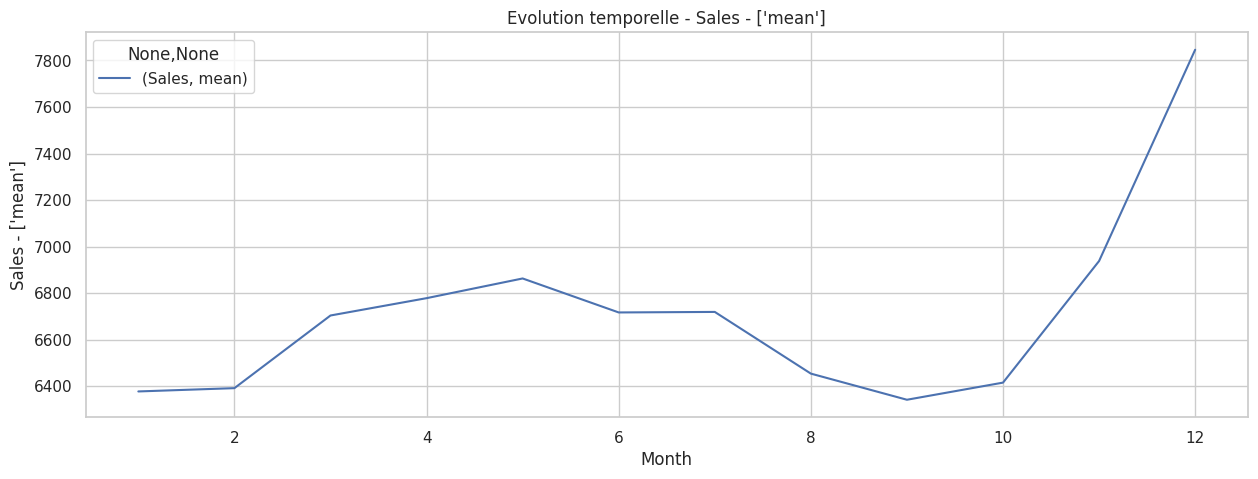

In [202]:
evolution_temp(
    df_filtered,
    date_col="Month",
    target_col="Sales",
    agg=["mean"],
    filter_date1=None,
)

En moyenne, vers la fin de l’année, les ventes commencent à augmenter fortement en raison des fêtes de fin d’année, qui représentent une période de forte activité commerciale pour les chaînes de magasins. Cela explique notamment la baisse importante des ventes observée au début de chaque année, après cette période de forte consommation. On observe ensuite une stabilisation des ventes à partir du mois de mars, qui se poursuit jusqu’au début des vacances d’été.